In [1]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
import cv2
import torch
from kaira.metrics.image import SSIM

ROOT = Path("/Users/marcellobullo/research/FINAL/github/djscc-playground")
RESULTS_DIR = ROOT / "results"
EXP_DIR = RESULTS_DIR / "djscc-psnr-vs-snr"

SNR_DIR_RE = re.compile(r"snr_?(-?\d+)\s*dB", re.IGNORECASE)
RESULT_IDX_RE = re.compile(r"_(\d+)\.png$", re.IGNORECASE)

WIDTH = 768
HEIGHT = 512

match = "index" 


mpl.rcdefaults()          # or plt.style.use("default")

/Users/marcellobullo/miniconda3/envs/demo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_rgb(path: Path, width: int, height: int) -> np.ndarray:
    """Load an image as an HxWx3 uint8 array (drops alpha if present)."""
    #return np.asarray(Image.open(path).convert("RGB"))
    image_bgr = np.array(Image.open(path))
    return cv2.resize(image_bgr, (width, height))


def load_originals(originals_dir: Path, width: int, height: int) -> dict[str, np.ndarray]:
    originals = {}
    for p in sorted(originals_dir.glob("*.png")):
        originals[p.stem] = load_rgb(p, width, height)
    if not originals:
        raise SystemExit(f"No PNG originals found in {originals_dir}")
    return originals

def psnr(a: np.ndarray, b: np.ndarray) -> float:
    """Standard RGB PSNR in dB (MAX=255). Returns inf for identical images."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10.0 * np.log10((255.0 ** 2) / mse)

def _unpack(summary):
    s0 = np.array([s[0] for s in summary])
    s1 = np.array([s[1] for s in summary])
    s2 = np.array([s[2] for s in summary])
    return s0, s1, s2

Loaded 24 originals from /Users/marcellobullo/Downloads/kodak_dataset


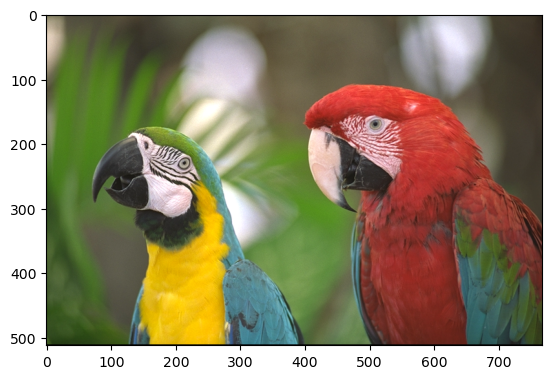

In [3]:
orig_path = "/Users/marcellobullo/Downloads/kodak_dataset"

originals = load_originals(Path(orig_path), WIDTH, HEIGHT)
print(f"Loaded {len(originals)} originals from {Path(orig_path)}")

img_idx = 23
img = originals[f"kodim{img_idx:02}"]
plt.imshow(img)
plt.show()

### Qualitatively Plots

In [4]:
snr_dirs = []
for d in sorted(EXP_DIR.iterdir()):
    if not d.is_dir():
        continue
    m = SNR_DIR_RE.search(d.name)
    if m:
        snr_dirs.append((int(m.group(1)), d))
snr_dirs.sort(key=lambda t: t[0])
if not snr_dirs:
    raise SystemExit(f"No snr_*dB sub-folders found in {EXP_DIR}")

#snr_dirs

rows = []          # per-image records for the CSV
psnr_summary = [] 

for snr, d in snr_dirs:
    vals = []
    #print(f"\nSNR {snr:>3} dB  ({d.name})")
    for img_path in sorted(d.glob("*.png")):
        #print("image path: ", img_path)
        recon = load_rgb(img_path, WIDTH, HEIGHT)
        img_index = int(img_path.with_suffix("").name.split("_")[1])
        original_name = f"kodim{img_index:02d}"
        original_img = originals.get(original_name)
        PSNR = psnr(recon, original_img)

        vals.append(PSNR)
        rows.append({"snr_db": snr, "result": img_path.name,
                        "matched_original": original_name,
                        "psnr_db": round(PSNR, 4)})
        #print(f"  {img_path.name:<18} -> {original_name}  PSNR {PSNR:6.2f} dB")
    if vals:
        arr = np.asarray(vals)
        psnr_summary.append((snr, float(arr.mean()), float(arr.std()), len(arr)))

# psnr_summary

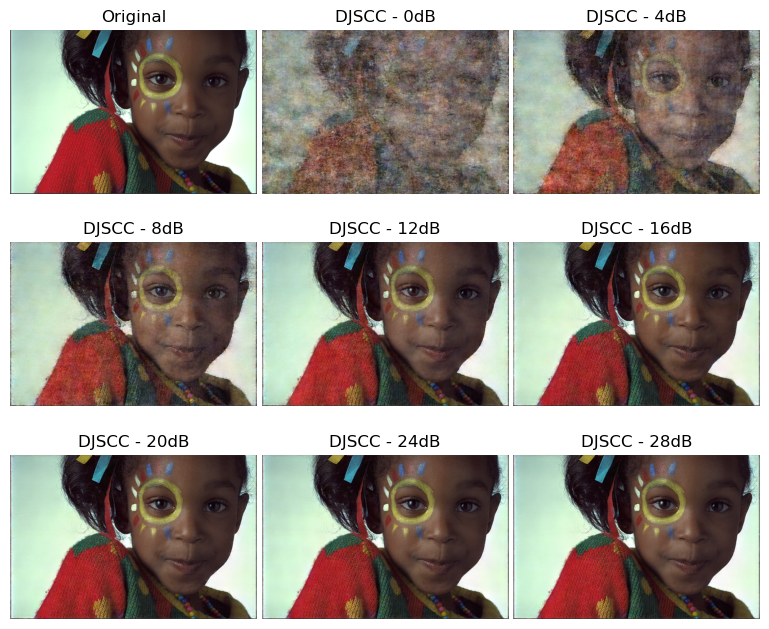

In [5]:
import math
import matplotlib.pyplot as plt

img_idx = 15
img_orig = originals[f"kodim{img_idx:02}"]

# 1. Determine total images and calculate grid dimensions
total_images = 1 + len(snr_dirs)
cols = 3  
rows = math.ceil(total_images / cols)

# 2. Create the grid (slightly smaller base size per image)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))

if total_images > 1:
    axes = axes.flatten()
else:
    axes = [axes]

# 3. Plot the original image
axes[0].imshow(img_orig)
axes[0].set_title("Original")
axes[0].axis('off')

# 4. Loop through snr_dirs and plot the rest
for i, (snr, d) in enumerate(snr_dirs):
    rec_images = sorted(d.glob("*.png"))
    img_rec = load_rgb(rec_images[img_idx-1], WIDTH, HEIGHT) 
    
    ax_idx = i + 1
    axes[ax_idx].imshow(img_rec)
    axes[ax_idx].set_title(f"DJSCC - {snr}dB")
    axes[ax_idx].axis('off')

# 5. Hide any empty subplots
for j in range(total_images, len(axes)):
    axes[j].axis('off')

# 6. Crush the whitespace
# wspace controls horizontal gaps, hspace controls vertical gaps
plt.subplots_adjust(wspace=0.02, hspace=0.0, left=0, right=1, bottom=0, top=0.85)
plt.savefig("/Users/marcellobullo/Downloads/kodim23_djscc_snr_comparison.png", dpi=600, bbox_inches='tight')

plt.show()

### Quantitatively Plots: PSNR and SSIM vs SNR over Kodak dataset

[]

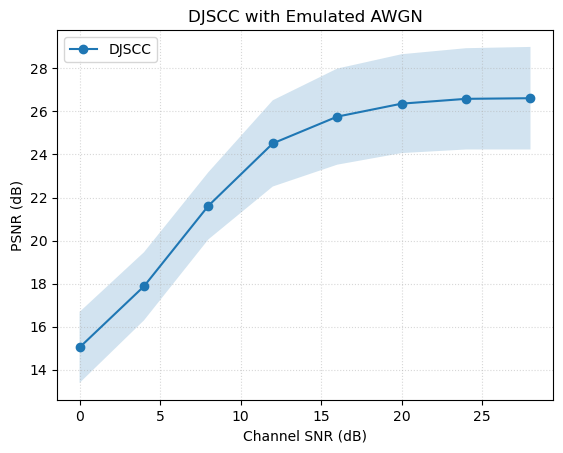

In [7]:
snrs = np.array([s[0] for s in psnr_summary])
psnr_mean = np.array([s[1] for s in psnr_summary])
psnr_std = np.array([s[2] for s in psnr_summary])

plt.plot(snrs, psnr_mean, "o-", label="DJSCC")
plt.fill_between(snrs, psnr_mean+psnr_std, psnr_mean-psnr_std, alpha=0.2)

plt.grid(linestyle=":", alpha=0.5)

plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("DJSCC with Emulated AWGN")
plt.legend()
plt.plot()

### Structural Similarity Index Measure (SSIM) 

In [8]:


SETTINGS = {
    "DJSCC": EXP_DIR,
}

device = ("mps" if torch.backends.mps.is_available()
         else "cuda" if torch.cuda.is_available() else "cpu")

kaira_ssim_model = SSIM(data_range=1.0).to(device).eval()

def img2tensor(img_uint8):
    """HxWx3 uint8 RGB -> 1x3xHxW float in [0,1] for the Kaira metrics."""
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1)
    return t.unsqueeze(0).float().div(255.0)


def get_folders(base):
    return sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d)
                   for d in base.iterdir()
                   if d.is_dir() and SNR_DIR_RE.search(d.name)),
                  key=lambda t: t[0])


@torch.no_grad()
def summarize_metric(base, metric):
    """Mean/std of a Kaira image metric vs SNR over the snr_*dB subfolders of `base`."""
    out = []
    for snr, d in get_folders(base):
        metric_values = []
        for img_path in sorted(d.glob("*.png")):
            idx = int(img_path.with_suffix("").name.split("_")[1])
            o = originals.get(f"kodim{idx:02d}")
            if o is None:                      # stray index w/o matching original
                continue
            x = img2tensor(load_rgb(img_path, WIDTH, HEIGHT)).to(device)
            y = img2tensor(o).to(device)
            metric_value = float(metric(x, y).mean().cpu())
            metric_values.append(metric_value)
        metric_values = np.asarray(metric_values)
        out.append((snr, metric_values.mean(), metric_values.std(), len(metric_values)))
    return out


# Compute SSIM
ssim_dict_values = {name: summarize_metric(base, kaira_ssim_model) for name, base in SETTINGS.items()}


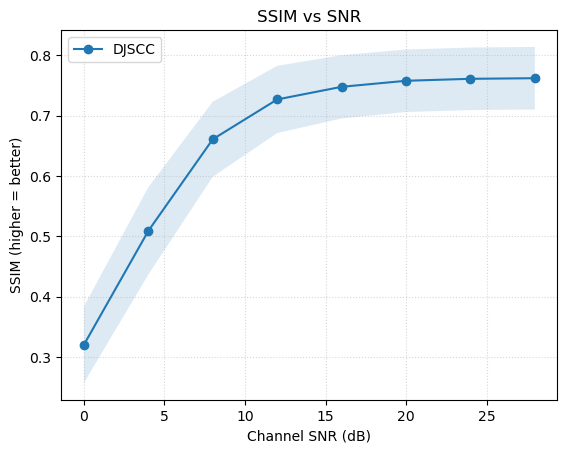

In [9]:
for name, ssim_summary in ssim_dict_values.items():
    snrs, ssim_mean, ssim_std = _unpack(ssim_summary)
    plt.plot(snrs, ssim_mean, "-o", label=name)
    plt.fill_between(snrs, ssim_mean + ssim_std, ssim_mean - ssim_std, alpha=0.15)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("SSIM (higher = better)")
plt.title("SSIM vs SNR")
plt.legend()
plt.show()

### Combined figure: PSNR and SSIM vs SNR side by side

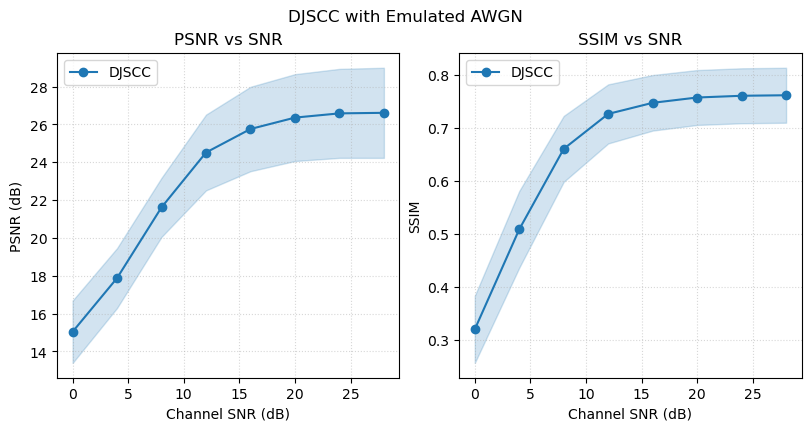

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), constrained_layout=True)

# left panel: PSNR vs SNR  (`summary` comes from the PSNR cell above)
snrs, psnr_mean, psnr_std = _unpack(psnr_summary)
axes[0].plot(snrs, psnr_mean, "-o", color="C0", label="DJSCC")
axes[0].fill_between(snrs, psnr_mean - psnr_std, psnr_mean + psnr_std, color="C0", alpha=0.2)
axes[0].set_ylabel("PSNR (dB)")
axes[0].set_title("PSNR vs SNR")

# right panel: SSIM vs SNR (one curve per entry of SETTINGS)
for i, (name, ssim_summary) in enumerate(ssim_dict_values.items()):
    ssim_snrs, ssim_mean, ssim_std = _unpack(ssim_summary)
    axes[1].plot(ssim_snrs, ssim_mean, "-o", color=f"C{i}", label=name)
    axes[1].fill_between(ssim_snrs, ssim_mean - ssim_std, ssim_mean + ssim_std, color=f"C{i}", alpha=0.2)
axes[1].set_ylabel("SSIM")
axes[1].set_title("SSIM vs SNR")

for ax in axes:
    ax.set_xlabel("Channel SNR (dB)")
    ax.grid(linestyle=":", alpha=0.5)
    ax.legend()

fig.suptitle("DJSCC with Emulated AWGN")
fig.savefig(RESULTS_DIR / "djscc_psnr_ssim_vs_snr.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
RESULTS_DIR

PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results')